# **Домашнее задание 2: Градиентный спуск (pro)**

В этом задании две части - теоретическая и практическая. Теорию можно набирать, используя LaTex или просто решать на листочке, сфотографировать и отправить вместе с заполненным ноутбуком в anytask.

Максимальный балл за домашнее задание - 10.

## Часть 1 (теоретическая)

## Задание 1 (**1.5 балла**)

В случае одномерной Ridge-регрессии минимизируется функция со штрафом:
$$Q(w) = (y-xw)^T(y-xw)+\lambda w^2,$$
где $\lambda$ - положительный параметр, штрафующий функцию за слишком большие значения $w$.

1)  (**0.5 балла**) Найдите производную $\nabla_w Q(w)$, выведите формулу для оптимального $w$.

**Решение:**

$$
Q(w) = (y^T - wx^T)(y-xw)+\lambda w^2 = y^Ty - y^Txw - wx^Ty + w^2x^Tx + \lambda w^2 =
$$
так как мы рассматриваем одномерный случай, $w$ — const, и тогда $y^Txw = w(y^Tx) = w(xy^T)$

$$
= y^Ty - 2wx^Ty + w^2x^Tx + \lambda w^2
$$

Производная по $w$:

$$\nabla_w Q(w) = 2wx^Tx + 2λw - 2x^Ty$$

Приравняем к 0:
$$\nabla_w Q(w) = 2wx^Tx + 2λw - 2x^Ty = 0$$
вытащим  $w$:

$$
w(x^Tx+λ) = x^Ty => w = x^Ty(x^Tx+λ)^{-1}
$$

2) (**0.5 балла**) Найдите вторую производную $\nabla^2_w Q(w)$. Убедитесь, что мы оказались в точке минимума.

$$\nabla^2_w Q(w) = (2wx^Tx + 2λw - 2x^Ty)' = 2x^Tx + 2\lambda > 0$$

Отсюда мы минимизируем $Q(w)$ выпуклую функцию => если экстремум найден — это минимум.


3) (**0.5 балла**) Выпишите шаг градиентного спуска в матричном виде.

$$
w_{i+1} = w_i - \eta(2w_i(x^Tx + \lambda) - 2x^Ty)
$$

## Часть 2 (практическая).

## Задание 2 (**1 балл**)

Дана функция: $$f(x) = x\cdot sin(5x) + 0.1 \cdot x^2$$

Для этой функции:

- [ ] Реализуйте (или возьмите рассмотренный на занятии) метод градиетного спуска с условием остановки `stop=1e^-6` и шагом `eta=0.001`. **Градиетный спуск обязательно должен сохранять траекторию движения.**
- [ ] Задайте стартовые точки x0, равные 0, 0.5, 1
- [ ] Реализуйте нахождение точек минимума и максимума функции $f(x)$ (для нахождения максимума нам нужно в направлении градиента, а не антиградиента)
- [ ] Проанализируйте результаты. Предположите, с чем они связаны. Ответьте на вопросы:
    - Чему равны значения экстремумов?
    - При старте из какой начальной точки найденные экстремумы совпадут?




### **Производная:**

$f'(x) = (x\cdot sin(5x) + 0.1 \cdot x^2)' = sin(5x) + 5xcos(5x) + 0.2x$

In [ ]:
import numpy as np
from sklearn.metrics import r2_score
# Функция и её производная
def f(x):

  return x*np.sin(5*x) + 0.1*x**2

def df(x):

    return np.sin(5*x) + 5*x*np.cos(5*x) + 0.2*x

# Градиентный спуск
def gradient_descent(f, df, x0, eta, max_iter=1000, tol=1e-6):

    x_curr = x0

    path = [x_curr]

    for i in range(max_iter):

      x_new = x_curr - eta*df(x_curr)

      if np.abs(x_new - x_curr) < tol:
        return x_curr, path

      x_curr = x_new

      path.append(x_curr)

    return x_curr, path

# Поиск экстремумов
def find_points(f, df, x0, eta, max_iter=1000, tol=1e-6):

    x_min, x_min_path = gradient_descent(f, df, x0, eta, max_iter, tol) # минимум просто вниз по функции

    # максимум
    x_curr = x0
    x_max_path = [x_curr]

    for i in range(max_iter):
      x_new = x_curr + eta*df(x_curr)

      if np.abs(x_new - x_curr) < tol:

        return x_curr, x_max_path, x_min, x_min_path

      x_curr = x_new

      x_max_path.append(x_curr)

    x_max = x_curr

    return x_max, x_max_path, x_min, x_min_path

In [ ]:
eta=0.001

for x0 in [0, 0.5, 1]:

  x_max, x_max_path, x_min, x_min_path = find_points(f, df, x0, eta, max_iter=1000, tol=1e-6)
  print(f'Стартовая точка: {x0}')
  print(f'X max: {x_max}')
  print(f'X min: {x_min}')


Стартовая точка: 0
X max: 0
X min: 0
Стартовая точка: 0.5
X max: 0.41185702181234396
X min: 0.975060876515715
Стартовая точка: 1
X max: 1.6035293061150784
X min: 0.9751376478508075


## Задание 3 (**0.5 балла**).
Напишите функцию, вычисляющую значение весов в линейной регрессии по точной (аналитически найденной) формуле.

In [ ]:
def ols_solution(X, y):

  X = np.hstack((np.ones((X.shape[0], 1)), X))

  return np.linalg.pinv(X.T@X)@X.T@y
    # your code here

## Задание 5 (**1 балл**).
Модифицируйте метод градиентного спуска с семинара так, чтобы это теперь был метод стохастического градиентного спуска.

In [ ]:
# с семинара
def compute_cost(X, y, theta):
    m = len(y)

    cost = (1./m) * (np.linalg.norm(X @ theta - y) ** 2)
    return cost

# с семинара

def gradient_descent(X, y, learning_rate, iterations):

    X = np.hstack((np.ones((X.shape[0], 1)), X))
    params = np.random.rand(X.shape[1])

    m = X.shape[0]

    cost_track = np.zeros((iterations,1))

    for i in range(iterations):
        params = params - 2./m * learning_rate * (X.T @ ((X @ params) - y))
        cost_track[i] = compute_cost(X, y, params)

    return cost_track, params


# По заданию
def stochastic_gradient_descent(X, y, learning_rate, iterations):

    X = np.hstack((np.ones((X.shape[0], 1)), X))
    params = np.random.rand(X.shape[1])

    m = X.shape[0]

    cost_track = np.zeros((iterations,1))

    for i in range(iterations):
        idx = np.random.randint(m)

        params = params - 2.* learning_rate * (X[idx:idx+1].T @ ((X[idx:idx+1] @ params) - y[idx:idx+1]))
        cost_track[i] = compute_cost(X[idx:idx+1], y[idx:idx+1], params)

    return cost_track, params

## Задание 6 (**3 балла**).
* **(0 баллов)**. Скопируйте метод градиентного спуска из семинара в этот ноутбук.

* **(0.5 балла)**. Обучите линейную регрессию на данных, сгенерированных ниже, тремя методами (по точной формуле, с помощью GD и с помощью SGD) на данных для задачи регрессии (см. код). Для GD и SGD используйте learning_rate = 0.01, iterations=10000.

* **(0.5 балла)**. С помощью каждого метода сделайте предсказание (на всех данных), вычислите качество предсказания r2 (from sklearn.metrics import r2_score). Для получения предсказания можете использовать функцию predict с семинара.


Ответьте на следующие вопросы (каждый вопрос - **0.5 балла**):

1) все ли методы справились с нахождением минимума? если нет, то почему какой-то из методов не справился?

2) сравните время работы методов (используйте библиотеку time): замеряйте время работы соответствующей написанной вами функции.

3) для методов GD и SGD нарисуйте графики (для каждого свой) зависимости ошибки (loss) от номера итерации.

4) какой метод успешнее всего справился с задачей? (т.е. r2 наибольший).

In [ ]:
def predict(X, params):
    X = np.hstack((np.ones((X.shape[0], 1)), X))
    return X @ params

In [ ]:
from sklearn.datasets import make_regression
import pandas as pd
import numpy as np

X, y, _ = make_regression(n_samples=100000,#number of samples
                          n_features=10,#number of features
                          n_informative=8,#number of useful features
                          noise=100,#bias and standard deviation of the guassian noise
                          coef=True,#true coefficient used to generated the data
                          random_state=123)

X = pd.DataFrame(data=X, columns=np.arange(0, X.shape[1]))
X[10] = X[6] + X[7] + np.random.random()*0.01

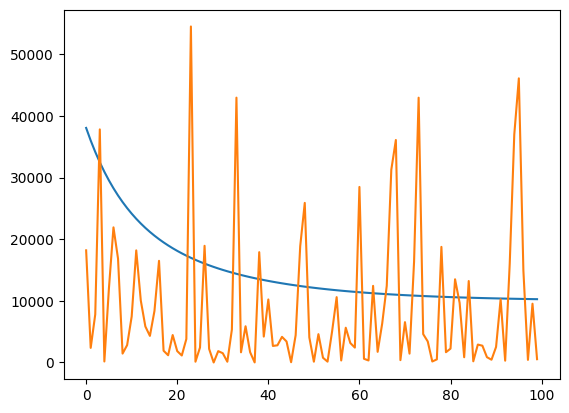

In [ ]:
import matplotlib.pyplot as plt


OLS = ols_solution(X, y)

track_GD, weights_GD = gradient_descent(X, y, 0.01, 100)
track_SGD, weights_SGD = stochastic_gradient_descent(X, y, 0.01, 100)


plt.plot(track_GD, label='GD')
plt.plot(track_SGD, label='SGD')

In [ ]:
gd_r2 = r2_score(y, predict(X, weights_GD))
sgd_r2 = r2_score(y, predict(X, weights_SGD))
ols_r2 = r2_score(y, predict(X, OLS))

print(f'GD r2: {gd_r2}')
print(f'SGD r2: {sgd_r2}')
print(f'OLS r2: {ols_r2}') # OLS

GD r2: 0.7483029600829627
SGD r2: 0.7020927308090732
OLS r2: 0.7554626185750483


your text here

## Задание 7 (1.5 балла).

* **(0.5 балла)**. Добавьте в функцию из задания 5 L2-регуляризацию и, соответственно, новый аргумент - коэффициент при регуляризаторе.

* **(1 балл)**. На сгенерированных выше данных обучите модифицированный алгоритм SGD с регуляризацией: в цикле перебирайте значения коэффициента регуляризации от 0.1 до 1 с шагом 0.1. Для каждого значения обучите модель и сделайте предсказание, выведите значение r2. Для какого значения коэффициента регуляризации получилось наилучшее качество r2, почему?

In [ ]:
# your code here
def stochastic_gradient_descent_l2(X, y, learning_rate, l2, iterations):

    X = np.hstack((np.ones((X.shape[0], 1)), X))
    weights = np.random.rand(X.shape[1])

    cost_track = np.zeros((iterations, 1))

    for i in range(iterations):
        elem_number = np.random.randint(0, len(X))
        weights_reg = weights.copy()
        weights_reg[0] = 0 # зануляем фиктивного товарища

        weights = weights - 2. * learning_rate * (X[elem_number] * ((X[elem_number] @ weights) - y[elem_number])) \
                - 2. * learning_rate * l2 * weights
        cost_track[i] = compute_cost(X, y, weights)

    return cost_track, weights

In [ ]:
print('Reg coef |   R2')
for reg_coef in np.arange(0.1, 1.1, 0.1):
    track_SGD, weights_SGD = stochastic_gradient_descent_l2(X, y, 0.01, reg_coef, 10000)
    pred_SGD = predict(X, weights_SGD)

    print(f' {reg_coef:.2f}    | {round(r2_score(y, pred_SGD), 3)}')



Reg coef |   R2
 0.10    | 0.731
 0.20    | 0.743
 0.30    | 0.698
 0.40    | 0.68
 0.50    | 0.627
 0.60    | 0.624
 0.70    | 0.645
 0.80    | 0.673
 0.90    | 0.675
 1.00    | 0.615


## Задание 8 (2 балла)

Реализуйте на выбор одну из оптимизаций градиентного спуска - Momentum или  AdaGrad. Необходимые выкладки вы можете подсмотреть [здесь](https://education.yandex.ru/handbook/ml/article/optimizaciya-v-ml).

Формула Momentum:


$$\theta_{t+1} = \theta_t - \alpha \nabla L(\theta_t) + \beta (\theta_t - \theta_{t-1})$$

Формула AdaGrad:

$$\theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{G_t + \epsilon}} \nabla L(\theta_t)$$

Где:
- $\alpha \nabla L(\theta_t)$ — классический GD
- $G_{t+1} = G_{t} + \nabla L(\theta_t)^2$ — сумма квадратов градиентов (накапливается)

- $\epsilon$ — небольшое значение Добавка ε на практике оставляется дефолтными 1e-8 и не изменяется ([c](https://education.yandex.ru/handbook/ml/article/optimizaciya-v-ml)).




In [ ]:
def momentum_gradient_descent(X, y, learning_rate, iterations, momentum):

    X = np.hstack((np.ones((X.shape[0], 1)), X))
    params = np.random.rand(X.shape[1])
    prew_params = params.copy()

    m = X.shape[0]

    cost_track = np.zeros((iterations,1))

    for i in range(iterations):

        new_params = params - 2./m * learning_rate * (X.T @ ((X @ params) - y)) + momentum*(params - prew_params)

        prew_params = params
        params = new_params

        cost_track[i] = compute_cost(X, y, params)

    return cost_track, params

In [ ]:
def adaptive_gradient_descent(X, y, learning_rate, iterations, epsilon=1e-8):

    X = np.hstack((np.ones((X.shape[0], 1)), X))
    params = np.random.rand(X.shape[1])
    gradient_sum_squares = np.zeros_like(params)

    m = X.shape[0]

    cost_track = np.zeros((iterations,1))

    for i in range(iterations):

        gradient = 2./m * learning_rate * (X.T @ ((X @ params) - y))

        gradient_sum_squares += gradient**2

        params = params - (learning_rate / (np.sqrt(gradient_sum_squares + epsilon))) * gradient

        cost_track[i] = compute_cost(X, y, params)

    return cost_track, params

## Бонус

## Задание 9 (0.5 балла)

Существует [метод Ньютона](https://en.wikipedia.org/wiki/Newton%27s_method_in_optimization) (метод второго порядка) для поиска минимума функции.

Известно, что методы второго порядка точнее, чем методы первого порядка (то есть те, которые используют только первую производную для оптимизации). Как вы думаете, почему в оптимизации функций потерь все формулы используют только производные первого порядка? Почему не используют метод Ньютона?

`Ваш ответ здесь`